Ukuran dataset awal: (614, 13)

Distribusi Kelas Target Awal (Y=Lancar, N=Berisiko):
Loan_Status
Y    422
N    192
Name: count, dtype: int64

File 'loan_data_cleaned.csv' berhasil dibuat!

Distribusi Latih Sebelum SMOTE: {1: np.int64(337), 0: np.int64(154)}
Distribusi Latih Sesudah SMOTE: {1: np.int64(337), 0: np.int64(337)}


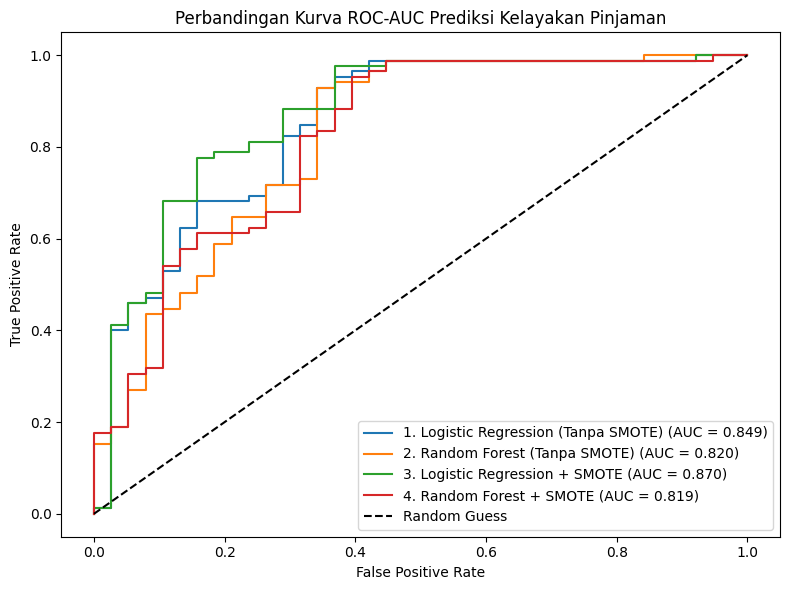


=== TABEL PERBANDINGAN PERFORMA MODEL ===
                      Skenario Model  Accuracy  Precision (Risiko)  Recall (Risiko)  F1-Score (Risiko)  ROC-AUC
1. Logistic Regression (Tanpa SMOTE)    0.8618              0.9565           0.5789             0.7213   0.8486
      2. Random Forest (Tanpa SMOTE)    0.8455              0.9130           0.5526             0.6885   0.8195
      3. Logistic Regression + SMOTE    0.8130              0.7143           0.6579             0.6849   0.8703
            4. Random Forest + SMOTE    0.7967              0.6970           0.6053             0.6479   0.8189


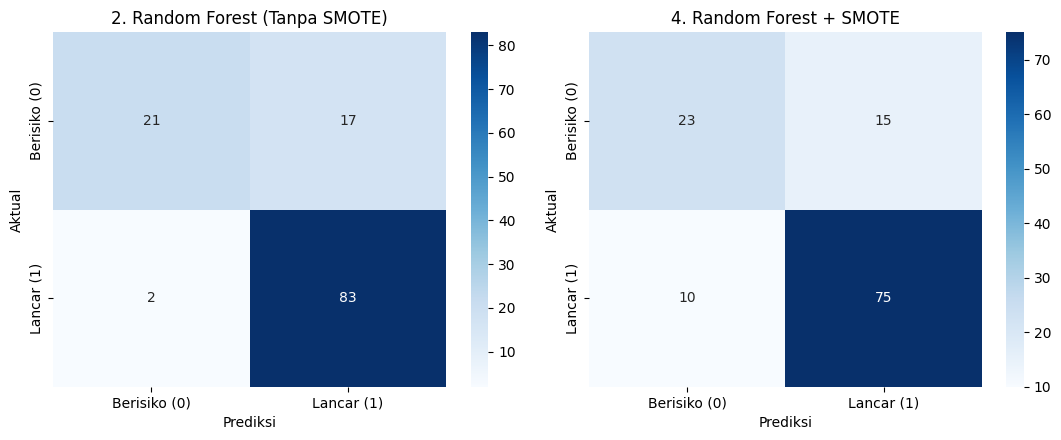

In [2]:
# 1. IMPORT LIBRARY
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve
)
from imblearn.over_sampling import SMOTE

# 2. LOAD DATASET
df = pd.read_csv("loan_data_raw.csv")
print("Ukuran dataset awal:", df.shape)
print("\nDistribusi Kelas Target Awal (Y=Lancar, N=Berisiko):")
print(df["Loan_Status"].value_counts())

# 3. DATA PREPROCESSING & CLEANING
df_clean = df.drop(columns=["Loan_ID"]).copy()

cat_cols = ["Gender", "Married", "Dependents", "Self_Employed", "Credit_History", "Loan_Amount_Term"]
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

df_clean["LoanAmount"] = df_clean["LoanAmount"].fillna(df_clean["LoanAmount"].median())
df_clean["Dependents"] = df_clean["Dependents"].replace("3+", "3").astype(int)

# Encoding: 0 = Berisiko/Ditolak (Kelas Minoritas), 1 = Lancar/Disetujui (Kelas Mayoritas)
df_clean["Gender"] = df_clean["Gender"].map({"Male": 1, "Female": 0})
df_clean["Married"] = df_clean["Married"].map({"Yes": 1, "No": 0})
df_clean["Education"] = df_clean["Education"].map({"Graduate": 1, "Not Graduate": 0})
df_clean["Self_Employed"] = df_clean["Self_Employed"].map({"Yes": 1, "No": 0})
df_clean["Loan_Status"] = df_clean["Loan_Status"].map({"Y": 1, "N": 0})

df_clean = pd.get_dummies(df_clean, columns=["Property_Area"], drop_first=True, dtype=int)
df_clean.to_csv("loan_data_cleaned.csv", index=False)
print("\nFile 'loan_data_cleaned.csv' berhasil dibuat!")

# 4. SPLITTING DATA (80% LATIH : 20% UJI) & SCALING
X = df_clean.drop(columns=["Loan_Status"])
y = df_clean["Loan_Status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. PENERAPAN SMOTE KHUSUS PADA DATA LATIH
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("\nDistribusi Latih Sebelum SMOTE:", dict(pd.Series(y_train).value_counts()))
print("Distribusi Latih Sesudah SMOTE:", dict(pd.Series(y_train_smote).value_counts()))

# 6. PELATIHAN & EVALUASI 4 SKENARIO MODEL
scenarios = {
    "1. Logistic Regression (Tanpa SMOTE)": (LogisticRegression(random_state=42), X_train_scaled, y_train),
    "2. Random Forest (Tanpa SMOTE)": (RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42), X_train_scaled, y_train),
    "3. Logistic Regression + SMOTE": (LogisticRegression(random_state=42), X_train_smote, y_train_smote),
    "4. Random Forest + SMOTE": (RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42), X_train_smote, y_train_smote),
}

results = []
plt.figure(figsize=(8, 6))

for name, (model, X_tr, y_tr) in scenarios.items():
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=0)
    rec = recall_score(y_test, y_pred, pos_label=0)
    f1 = f1_score(y_test, y_pred, pos_label=0)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Skenario Model": name,
        "Accuracy": round(acc, 4),
        "Precision (Risiko)": round(prec, 4),
        "Recall (Risiko)": round(rec, 4),
        "F1-Score (Risiko)": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })

    fpr, tpr, _ = roc_curve(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Perbandingan Kurva ROC-AUC Prediksi Kelayakan Pinjaman")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=300)
plt.show()

results_df = pd.DataFrame(results)
print("\n=== TABEL PERBANDINGAN PERFORMA MODEL ===")
print(results_df.to_string(index=False))

# 7. VISUALISASI CONFUSION MATRIX
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for idx, key in enumerate(["2. Random Forest (Tanpa SMOTE)", "4. Random Forest + SMOTE"]):
    model, X_tr, y_tr = scenarios[key]
    cm = confusion_matrix(y_test, model.predict(X_test_scaled))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[idx],
                xticklabels=["Berisiko (0)", "Lancar (1)"],
                yticklabels=["Berisiko (0)", "Lancar (1)"])
    axes[idx].set_title(key)
    axes[idx].set_xlabel("Prediksi")
    axes[idx].set_ylabel("Aktual")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300)
plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')